In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
# Global style — consistent across all figures
plt.rcParams.update({
    "figure.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

PRIMARY   = "#2C6E9E"   # blue for histograms / scatter
SECONDARY = "#E07B39"   # orange for accent plots

In [3]:
# Load the cleaned dataset
data_clean = pd.read_csv("../data/processed/vehicle_co2_clean.csv")

print("Number of rows:", len(data_clean))
print("Number of columns:", len(data_clean.columns))
data_clean.head()

Number of rows: 5985
Number of columns: 14


,make,model,vehicle_class,engine_size,cylinders,transmission,fuel_type,co2,transmission_gears,transmission_type,engine_per_cylinder,engine_x_cylinders,engine_size_sq,cylinders_sq
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,196,5.0,AS,0.500000,8.0,4.00,16
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,221,6.0,M,0.600000,9.6,5.76,16
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,136,7.0,AV,0.375000,6.0,2.25,16
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,255,6.0,AS,0.583333,21.0,12.25,36
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,244,6.0,AS,0.583333,21.0,12.25,36


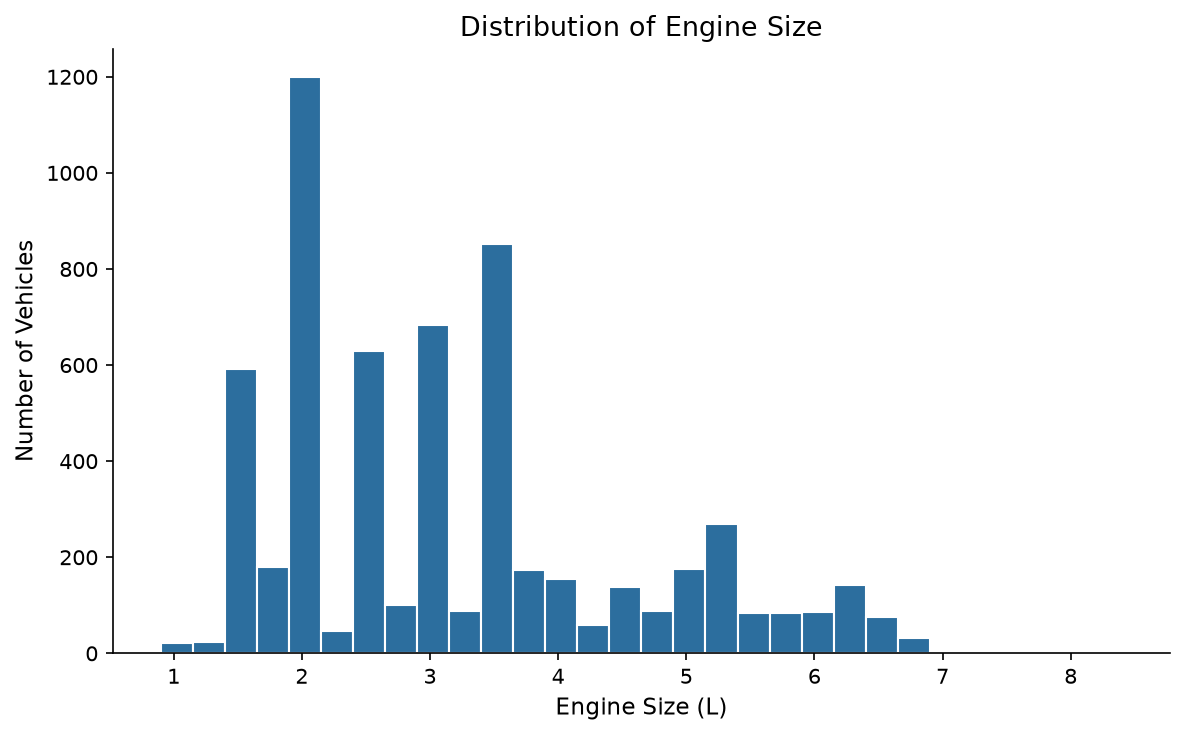

In [4]:
# Distribution of Engine Size

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(data_clean["engine_size"], bins=30, color=PRIMARY, edgecolor="white")
ax.set_xlabel("Engine Size (L)")
ax.set_ylabel("Number of Vehicles")
ax.set_title("Distribution of Engine Size")
plt.tight_layout()

plt.savefig("../results/figures/engine_size_distribution.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
plt.close()

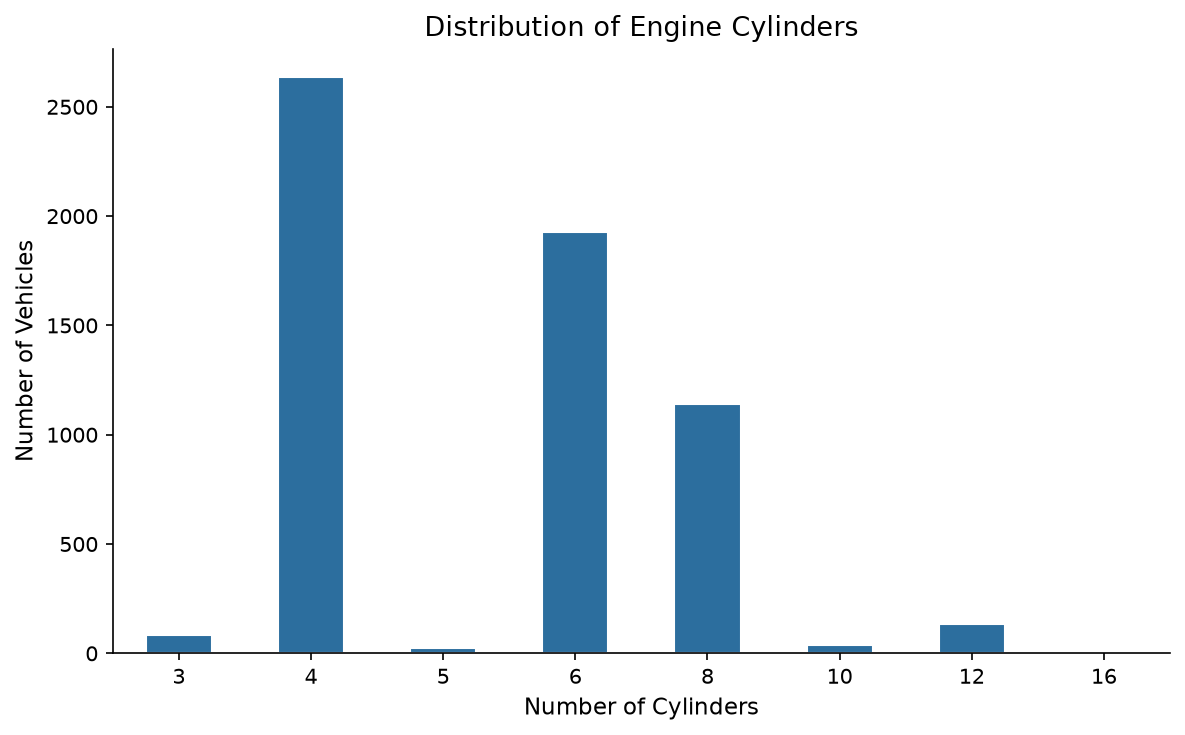

In [5]:
# Distribution of Cylinders

fig, ax = plt.subplots(figsize=(8, 5))

data_clean["cylinders"].value_counts().sort_index().plot(
    kind="bar", ax=ax, color=PRIMARY, edgecolor="white"
)
ax.set_xlabel("Number of Cylinders")
ax.set_ylabel("Number of Vehicles")
ax.set_title("Distribution of Engine Cylinders")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()

plt.savefig("../results/figures/cylinders_distribution.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
plt.close()

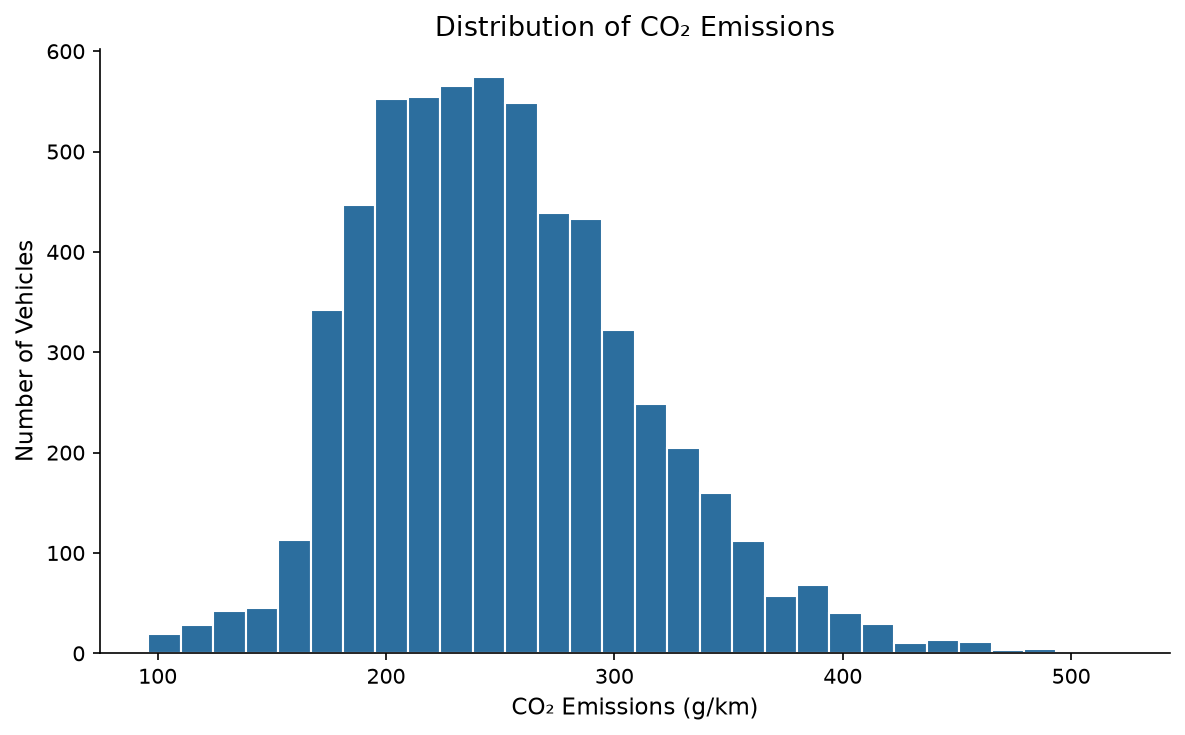

In [6]:
# Distribution of CO₂ Emissions

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(data_clean["co2"], bins=30, color=PRIMARY, edgecolor="white")
ax.set_xlabel("CO₂ Emissions (g/km)")
ax.set_ylabel("Number of Vehicles")
ax.set_title("Distribution of CO₂ Emissions")
plt.tight_layout()

plt.savefig("../results/figures/co2_distribution.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
plt.close()

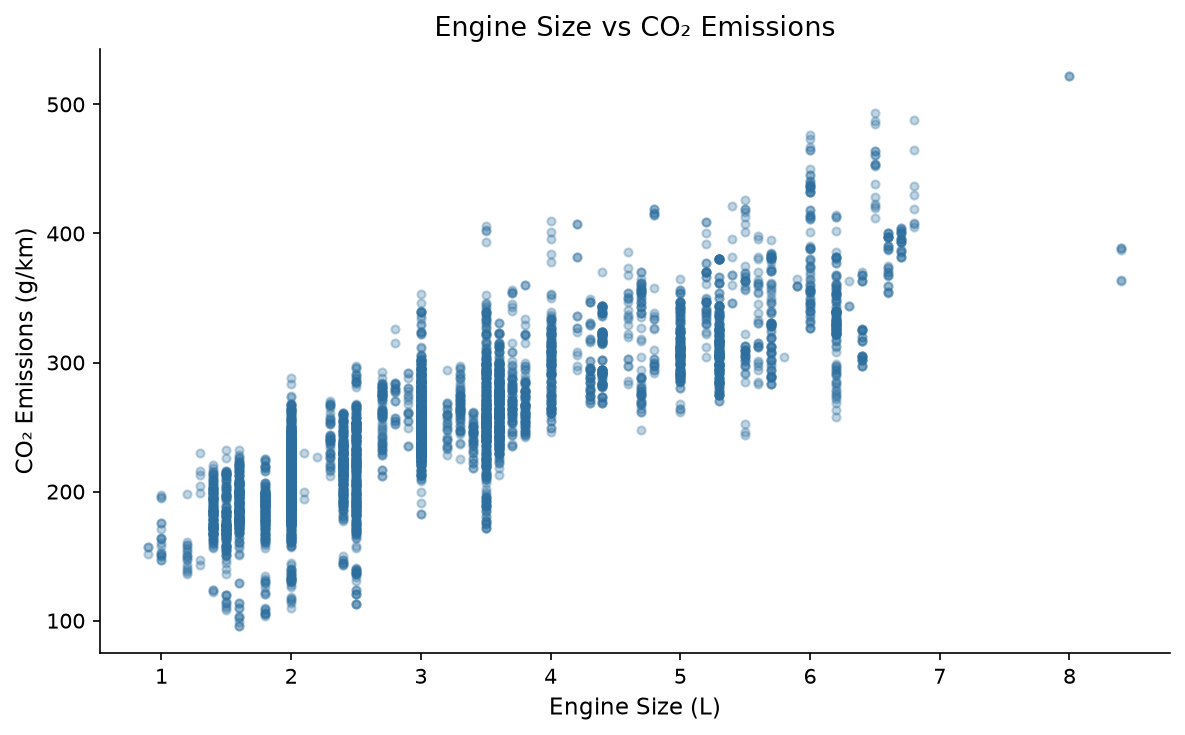

In [7]:
# Engine Size vs CO₂ Emissions

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(data_clean["engine_size"], data_clean["co2"],
           alpha=0.3, color=PRIMARY, s=15)
ax.set_xlabel("Engine Size (L)")
ax.set_ylabel("CO₂ Emissions (g/km)")
ax.set_title("Engine Size vs CO₂ Emissions")
plt.tight_layout()

plt.savefig("../results/figures/engine_size_vs_co2.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
plt.close()

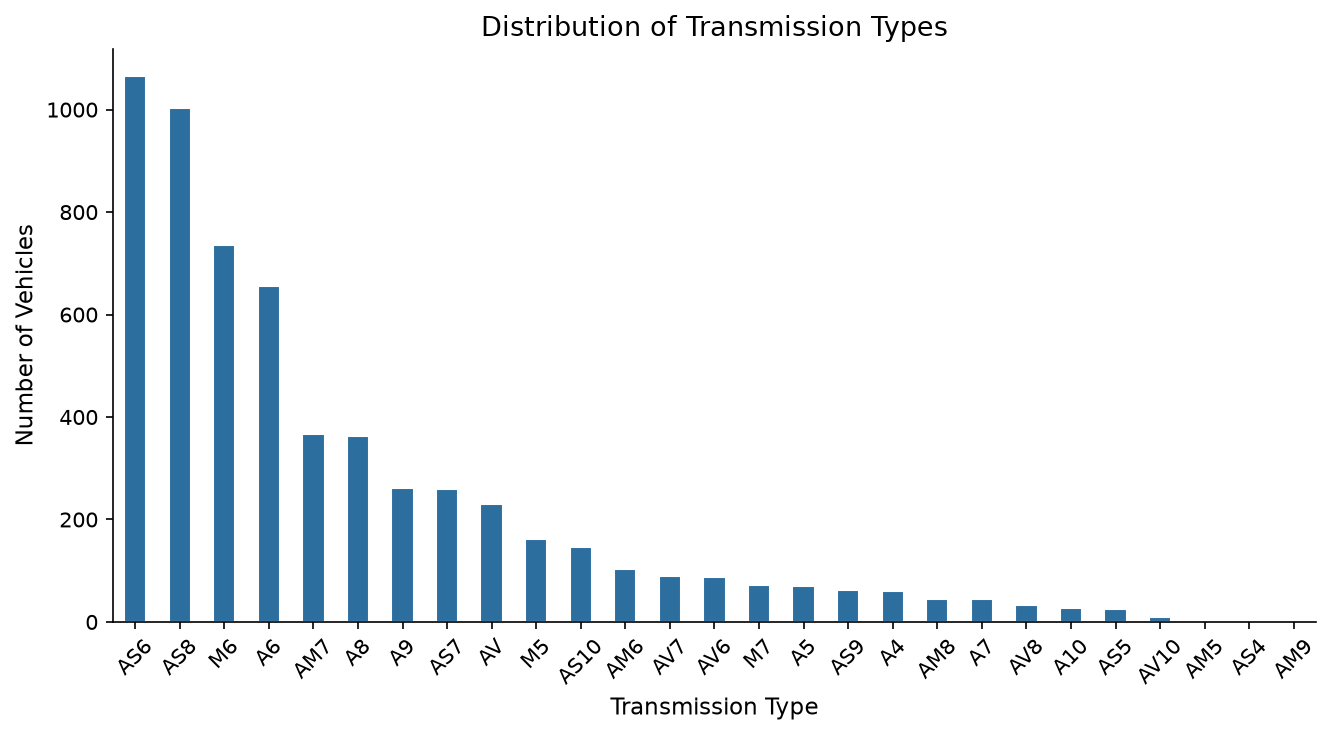

In [8]:
# Distribution of Transmission Types

fig, ax = plt.subplots(figsize=(9, 5))

data_clean["transmission"].value_counts().plot(
    kind="bar",
    ax=ax,
    color=PRIMARY,
    edgecolor="white"
)

ax.set_xlabel("Transmission Type")
ax.set_ylabel("Number of Vehicles")
ax.set_title("Distribution of Transmission Types")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()

plt.savefig(
    "../results/figures/transmission_distribution.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()

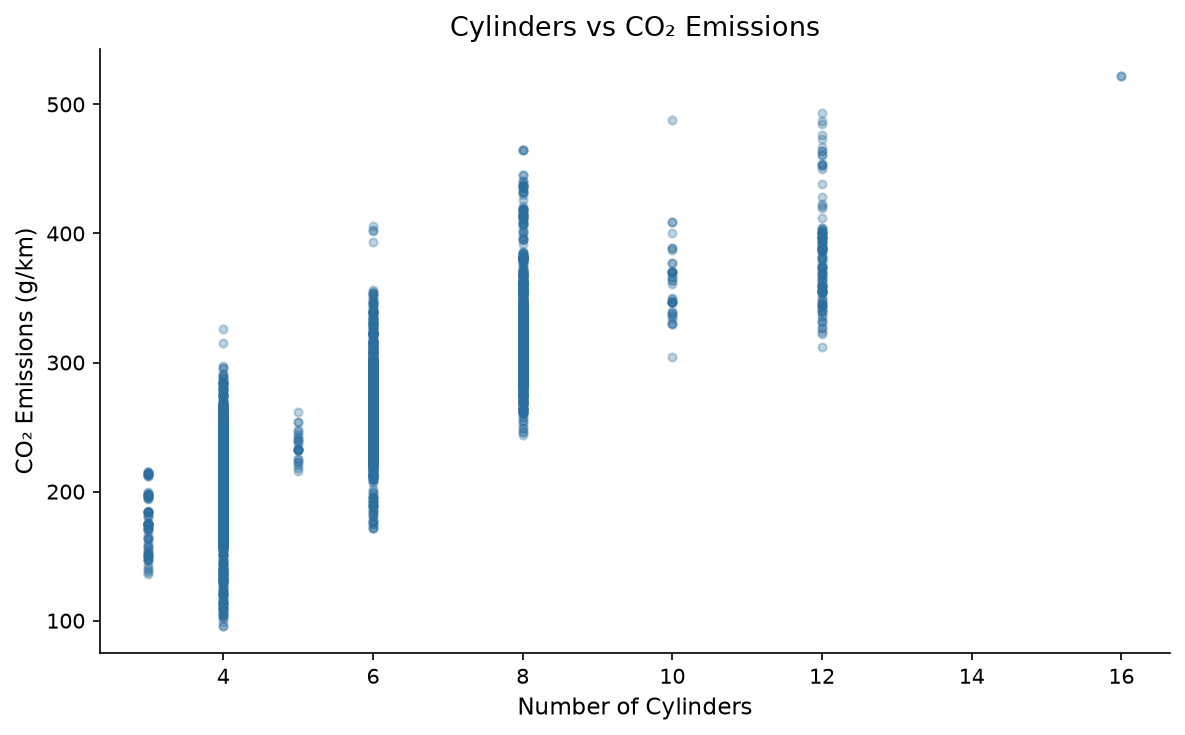

In [9]:
# Cylinders vs CO₂ Emissions

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(data_clean["cylinders"], data_clean["co2"],
           alpha=0.3, color=PRIMARY, s=15)
ax.set_xlabel("Number of Cylinders")
ax.set_ylabel("CO₂ Emissions (g/km)")
ax.set_title("Cylinders vs CO₂ Emissions")
plt.tight_layout()

plt.savefig("../results/figures/cylinders_vs_co2.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
plt.close()

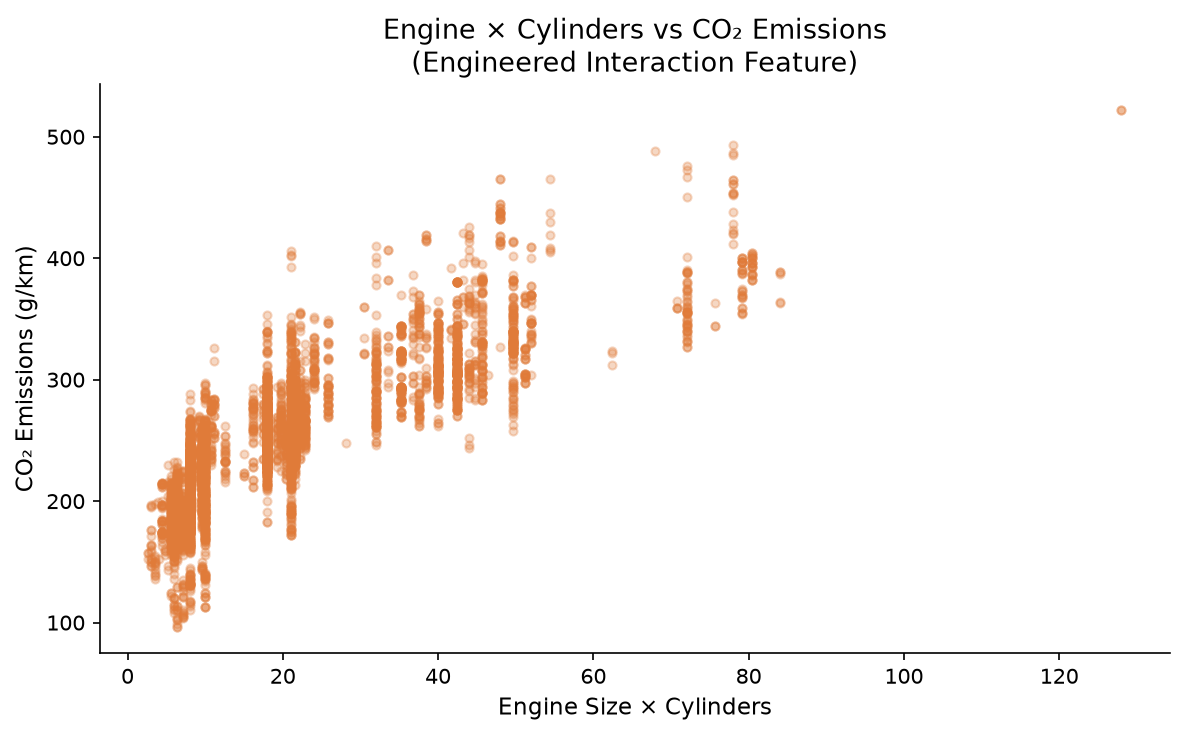

In [10]:
# Engine × Cylinders vs CO₂ — key engineered feature

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(data_clean["engine_x_cylinders"], data_clean["co2"],
           alpha=0.3, color=SECONDARY, s=15)
ax.set_xlabel("Engine Size × Cylinders")
ax.set_ylabel("CO₂ Emissions (g/km)")
ax.set_title("Engine × Cylinders vs CO₂ Emissions\n"
    "(Engineered Interaction Feature)")
plt.tight_layout()

plt.savefig("../results/figures/engine_x_cylinders_vs_co2.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
plt.close()

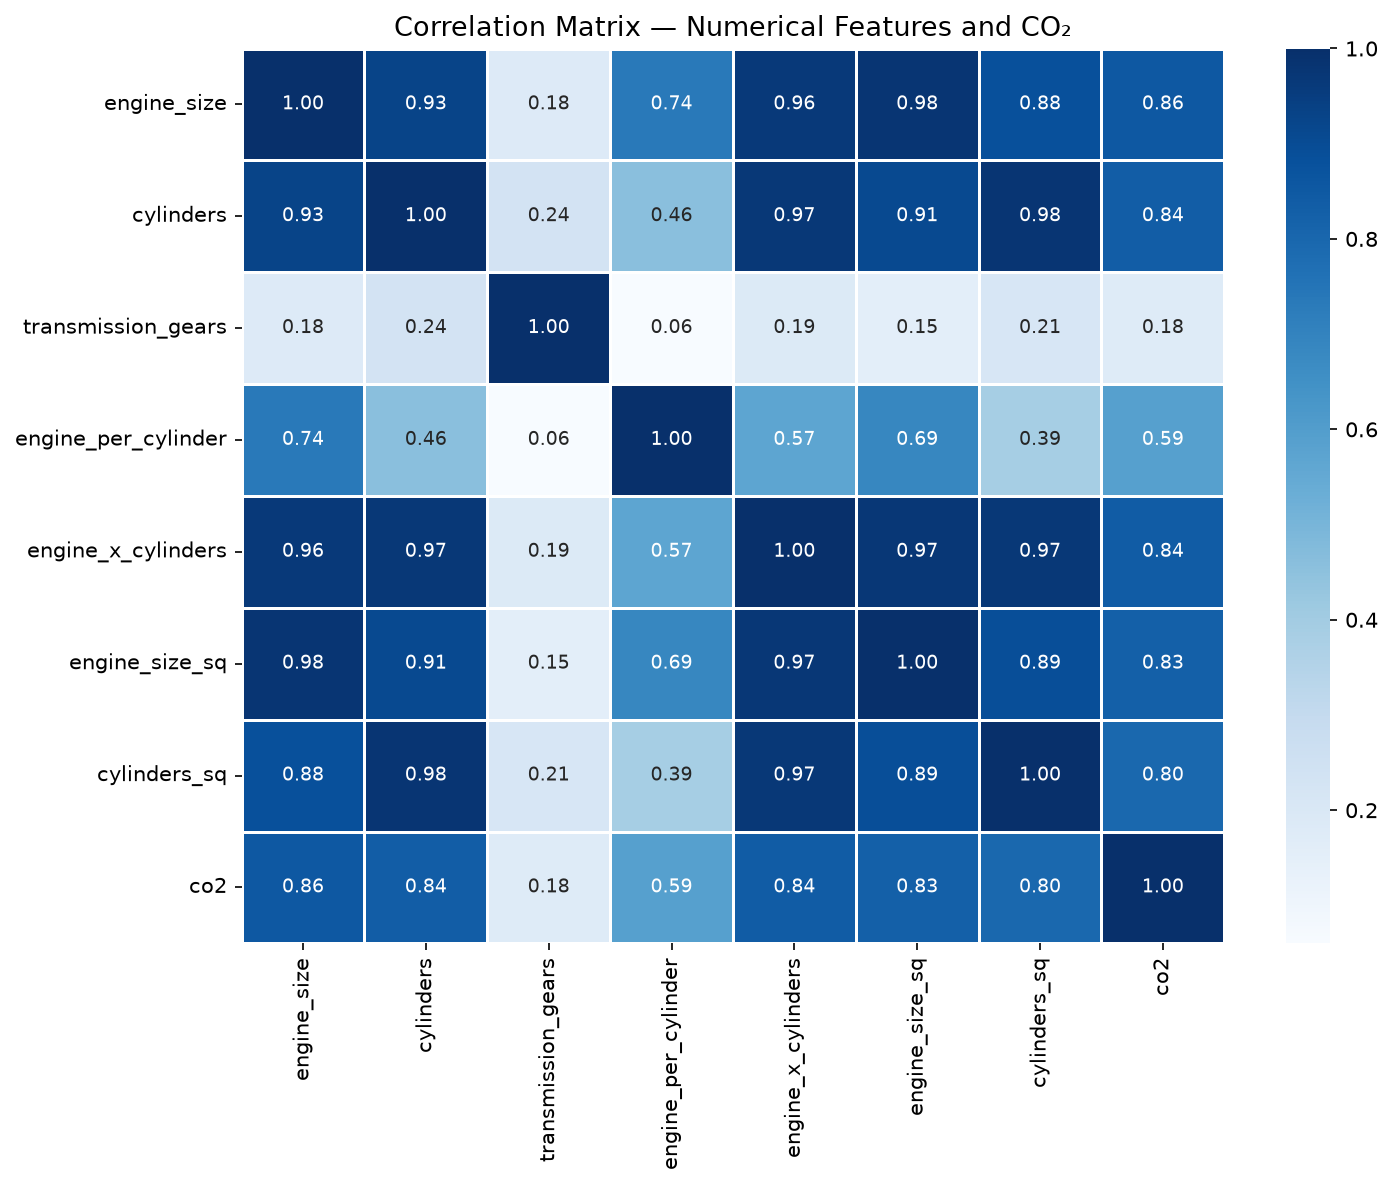

In [11]:
# Correlation heatmap — numerical features only

numerical_cols = [
    "engine_size",
    "cylinders",
    "transmission_gears",
    "engine_per_cylinder",
    "engine_x_cylinders",
    "engine_size_sq",
    "cylinders_sq",
    "co2"
]

corr_matrix = data_clean[numerical_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    ax=ax,
    linewidths=0.5,
    annot_kws={"size": 9}
)

ax.set_title("Correlation Matrix — Numerical Features and CO₂")
plt.tight_layout()

plt.savefig("../results/figures/correlation_heatmap.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
plt.close()

In [12]:
# Summary statistics for key variables

print("=" * 50)
print("Summary Statistics — Key Features")
print("=" * 50)
print(data_clean[[
    "engine_size", "cylinders", "transmission_gears",
    "engine_x_cylinders", "co2"
]].describe().round(3))

Summary Statistics — Key Features
       engine_size  cylinders  transmission_gears  engine_x_cylinders  \
count     5985.000   5985.000            5985.000            5985.000   
mean         3.160      5.616               6.843              20.100   
std          1.368      1.853               1.208              15.603   
min          0.900      3.000               4.000               2.700   
25%          2.000      4.000               6.000               8.000   
50%          3.000      6.000               6.000              18.000   
75%          3.700      6.000               8.000              22.200   
max          8.400     16.000              10.000             128.000   

            co2  
count  5985.000  
mean    250.918  
std      59.330  
min      96.000  
25%     207.000  
50%     245.000  
75%     288.000  
max     522.000  
